# Attention

I'm working through attention by following the numbers: inputs → query/key/value projections → scores → weights → mixed values. Each display is produced by a short call to `attention_visuals.py`, using small tensors or outputs from the attention classes. Plotting, controls and demonstration fixtures live in that separate file.

Read each matrix with **queries down the rows** and **keys across the columns**. A row answers: which values does this query read? The notebook includes interactive query, head and mask controls, plus saved figures that remain readable without the controls.

All attention implementations stay in `src/attention_is_all_you_need/attention.py` and are importable from `attention.py`. The notebook imports those classes and calls the separate display functions. It contains no plotting definitions or control setup. Sources are in `docs/SOURCES.md`.

Start from the project directory with `uv run --frozen --extra notebook jupyter lab attention_mechanism.ipynb`, select the Python kernel and run cells in order. The examples use small CPU tensors and randomly initialized layers.


In [1]:
from pathlib import Path
import sys

root = Path.cwd()
if not (root / "attention.py").is_file():
    raise RuntimeError("Start this notebook from the attention-is-all-you-need project directory.")
sys.path.insert(0, str(root))
sys.path.insert(0, str(root / "src"))

import torch
from attention import (
    Attention, SingleHeadAttention, MultiHeadAttention, SelfAttentionEncoder,
    SelfAttention, CrossAttention, make_attention_mask, scaled_dot_product_attention,
)

torch.manual_seed(7)
torch.set_printoptions(precision=4, sci_mode=False)
print("PyTorch:", torch.__version__, "| device: CPU | seed: 7")


PyTorch: 2.14.1+cpu | device: CPU | seed: 7


In [2]:
import attention_visuals as vis
vis.configure()


## 1. Attention starts with a weighted average

A **query** says what one token is looking for. **Keys** describe the tokens it can compare with. **Values** contain the information to mix. A query-key dot product gives a score; softmax turns scores into positive weights that sum to one.

For head width $d_k$, the calculation is

$$S = QK^T / \sqrt{d_k},\qquad A = \operatorname{softmax}(S),\qquad C = AV.$$

Here $Q$ has shape `(batch, queries, width)`, $K$ has `(batch, keys, width)` and $V$ has `(batch, keys, value width)`. Scores and weights have `(batch, queries, keys)` shape. Softmax runs across keys: each query gets its own weighted average.

With zero query scores, two keys have equal weight. Values `[2, 4]` and `[6, 8]` therefore give `0.5*[2, 4] + 0.5*[6, 8] = [4, 6]`.


In [3]:
q = torch.zeros(1, 1, 2)
k = torch.tensor([[[1., 0.], [0., 1.]]])
v = torch.tensor([[[2., 4.], [6., 8.]]])
context, weights = scaled_dot_product_attention(q, k, v)
print("Weights:", weights)
print("Row sums:", weights.sum(-1))
print("Context:", context)
torch.testing.assert_close(context, torch.tensor([[[4., 6.]]]))


Weights: tensor([[[0.5000, 0.5000]]])
Row sums: tensor([[1.]])
Context: tensor([[[4., 6.]]])


### See the weighted average

The left chart shows the weights. The stacked bars on the right show exactly how each value contributes to each output feature; the stack height is the context value.


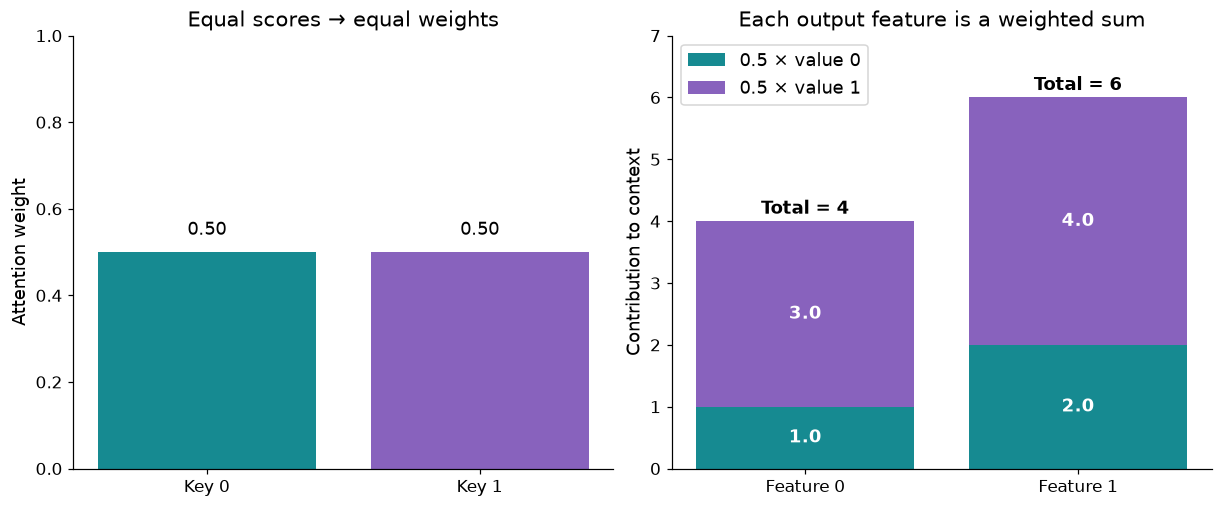

In [4]:
vis.show_weighted_average(weights, v, context)


### Read matrix multiplication as rows meeting columns

`A @ B` is a collection of dot products. The number of columns in A must equal the number of rows in B; the result keeps A's row count and B's column count. The orange row in A and orange column in B produce the orange cell in C.

These A and B are arbitrary small matrices. Later, A will name the attention-weight matrix. Python `@` multiplies matrices; `*` would multiply matching entries element by element. Try the selected cell yourself: `1×6 + 2×8 = 22`.


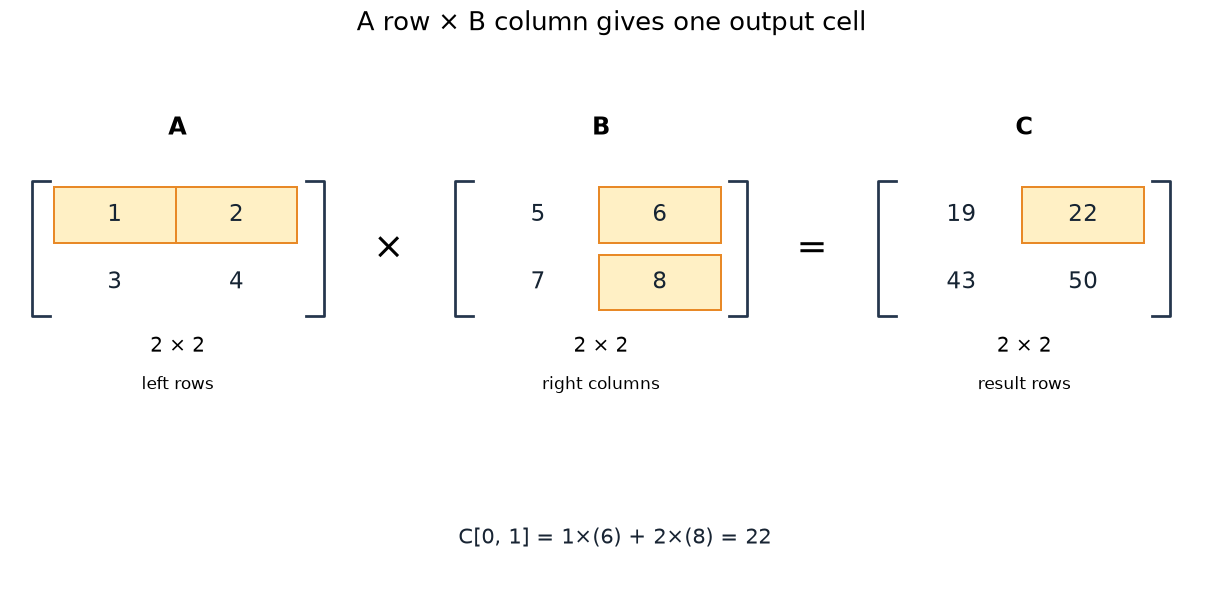

In [5]:
vis.show_matrix_product()


## 2. Change the query

Use query `[1, 0]`. Its dot products with the two keys are `[1, 0]`. After division by $\sqrt{2}$, scores are about `[0.7071, 0]`, giving weights about `[0.6698, 0.3302]`. The first value now matters more. Predict the output before running this cell.

The divisor uses **head width**, not full embedding width. It controls how large the scores become as each dot product adds more terms.


In [6]:
q = torch.tensor([[[1., 0.]]])
scores = (q @ k.transpose(-2, -1)) / (q.shape[-1] ** 0.5)
context, weights = scaled_dot_product_attention(q, k, v)
print("Scaled scores:", scores)
print("Weights:", weights)
print("Context:", context)
print("Expected context: approximately [3.321, 5.321]")


Scaled scores: tensor([[[0.7071, 0.0000]]])
Weights: tensor([[[0.6698, 0.3302]]])
Context: tensor([[[3.3210, 5.3210]]])
Expected context: approximately [3.321, 5.321]


### Follow a dot product into one matrix cell

In the next toy example, Q and K each have three rows and two features. Orange outlines identify one query row, one key column in Kᵀ and their score cell. Change the row controls and calculate the two products before reading the result. The next figure then shows all scores, their row-wise softmax and the mixed values.


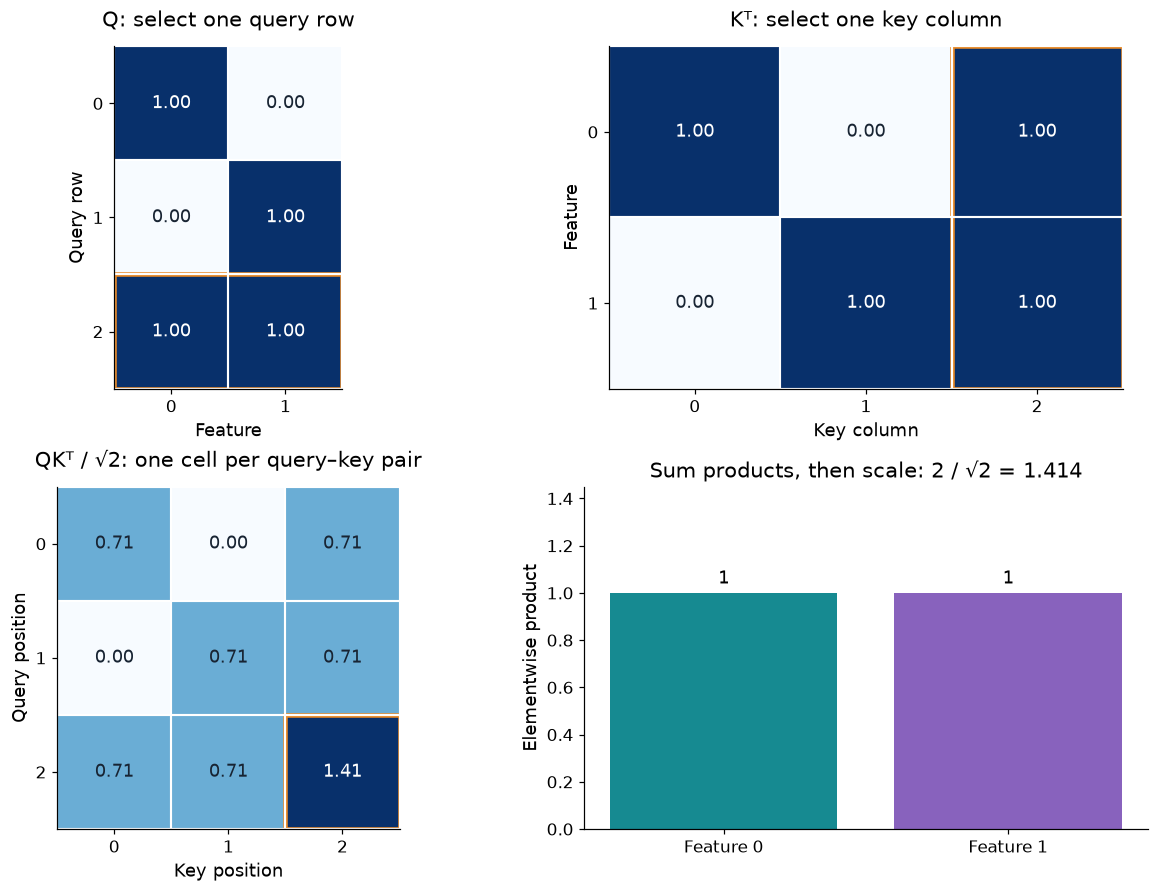

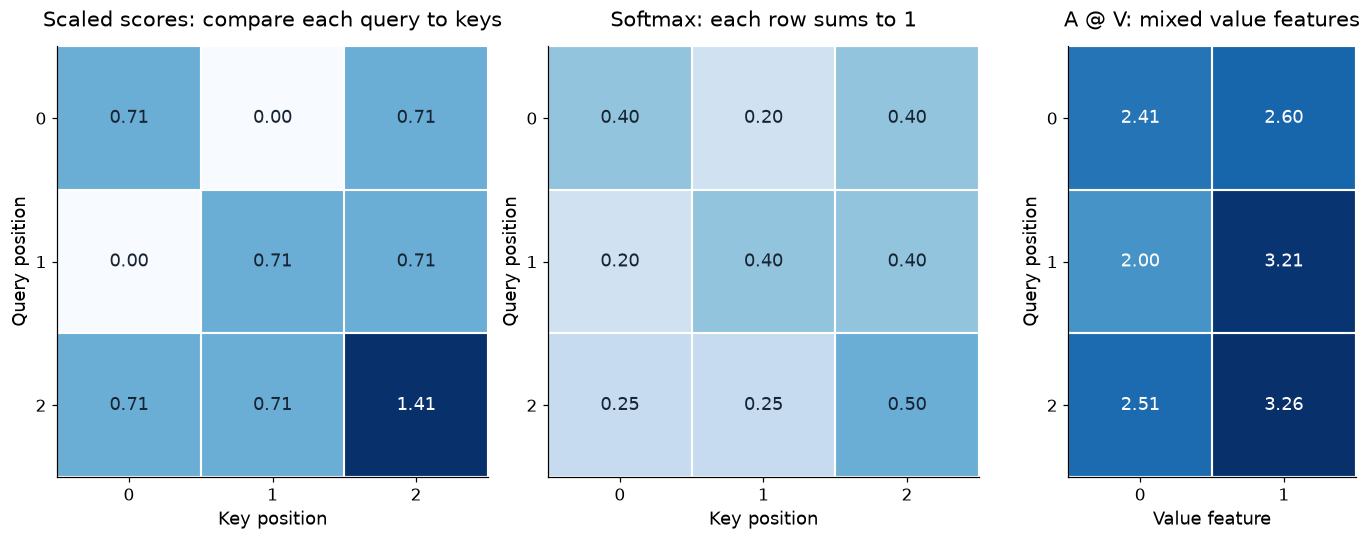

In [7]:
dot_controls = vis.show_dot_products()


### Change direction and concentration

Rotate the query to change which keys it matches. Vector length also affects the dot product: K2 has length √2, while K0 and K1 have length 1.

Temperature is an exploration control for this toy calculation: dividing scores by a smaller positive temperature concentrates the distribution; a larger one spreads it out. It is implemented by rescaling the toy query before calling the same attention function. It does not change the Attention class API. The star is the weighted value vector, which stays inside the value triangle because the weights are nonnegative and sum to one.


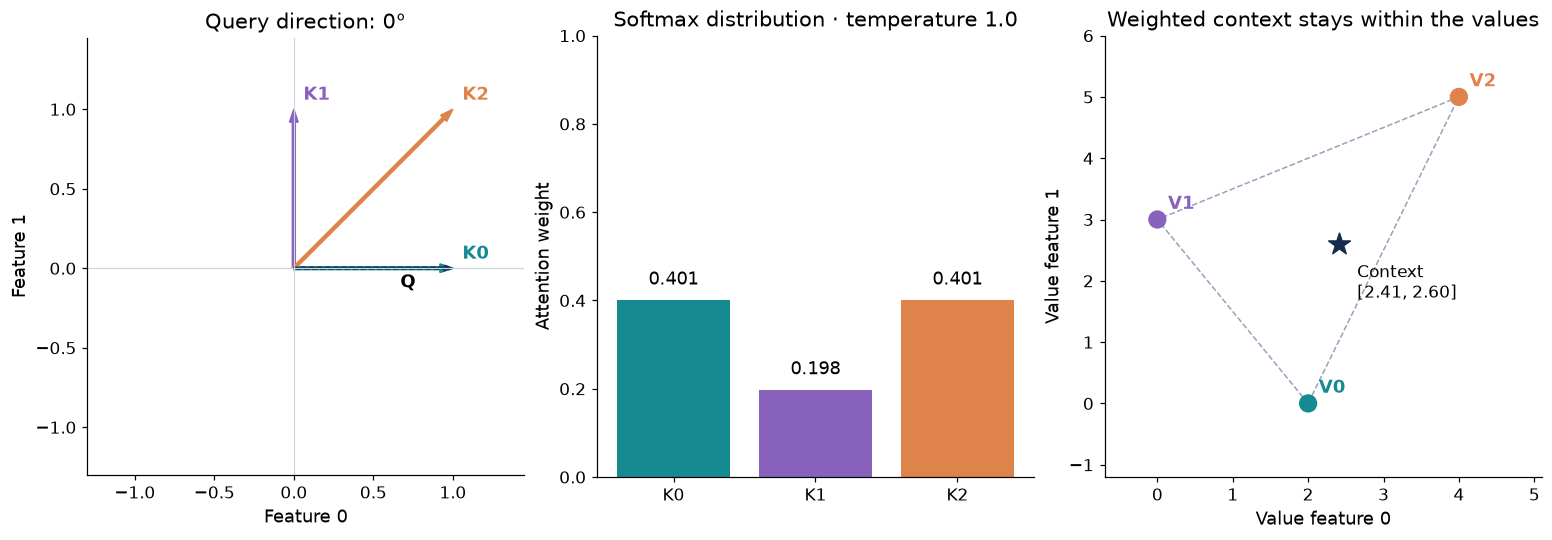

In [8]:
query_controls = vis.show_query_explorer()


### Why divide by the square root of head width?

For independent zero-mean, unit-variance query/key components, each product has variance 1. Summing d independent products gives variance d and standard deviation √d. Dividing by √d returns variance to about 1.

The plot checks this on 8,192 independent Gaussian query/key pairs per width. This is a controlled numerical example; learned projections need not satisfy those assumptions exactly. The divisor is the width of each head, not the combined embedding width.


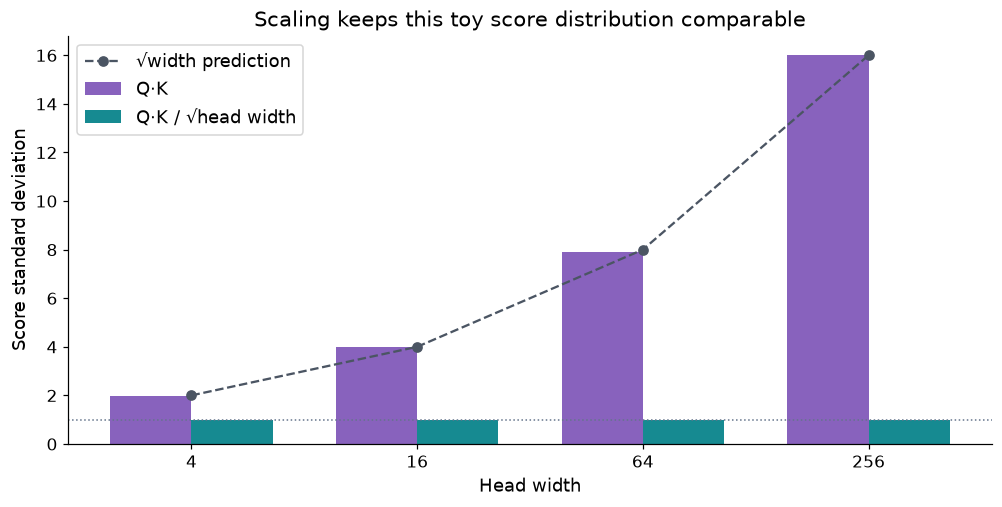

In [9]:
vis.show_head_width_scaling()


### Let input X fill all three roles

Attention also works before introducing learned projections. Set Q = K = V = X: input rows compare directly with one another, then each row retrieves a weighted mixture of those same input rows.

Compute `X @ X.transpose(-2, -1)`, divide by √feature width, apply softmax across keys, then multiply the weights by X. No parameters are created or trained in this calculation. The following learned projections let each token take on different query, key and value representations.

In [10]:
raw_x = torch.tensor([[[1., 0.], [0., 1.], [1., 1.]]])
raw_context, raw_weights = scaled_dot_product_attention(raw_x, raw_x, raw_x)
print("Scaled input similarities:\n", (raw_x @ raw_x.transpose(-2, -1)) / (2 ** 0.5))
print("Attention weights:\n", raw_weights)
print("Context (weights @ X):\n", raw_context)


Scaled input similarities:
 tensor([[[0.7071, 0.0000, 0.7071],
         [0.0000, 0.7071, 0.7071],
         [0.7071, 0.7071, 1.4142]]])
Attention weights:
 tensor([[[0.4011, 0.1978, 0.4011],
         [0.1978, 0.4011, 0.4011],
         [0.2483, 0.2483, 0.5035]]])
Context (weights @ X):
 tensor([[[0.8022, 0.5989],
         [0.5989, 0.8022],
         [0.7517, 0.7517]]])


### Follow the two matrix products

The first display shows `X × Xᵀ = R`. R contains raw dot products; dividing by √2 and normalizing each row gives A, printed above. The second display shows `A × X = Context`. Here the value matrix is the original input itself. Numbers are rounded for display; calculations use the full tensor precision.

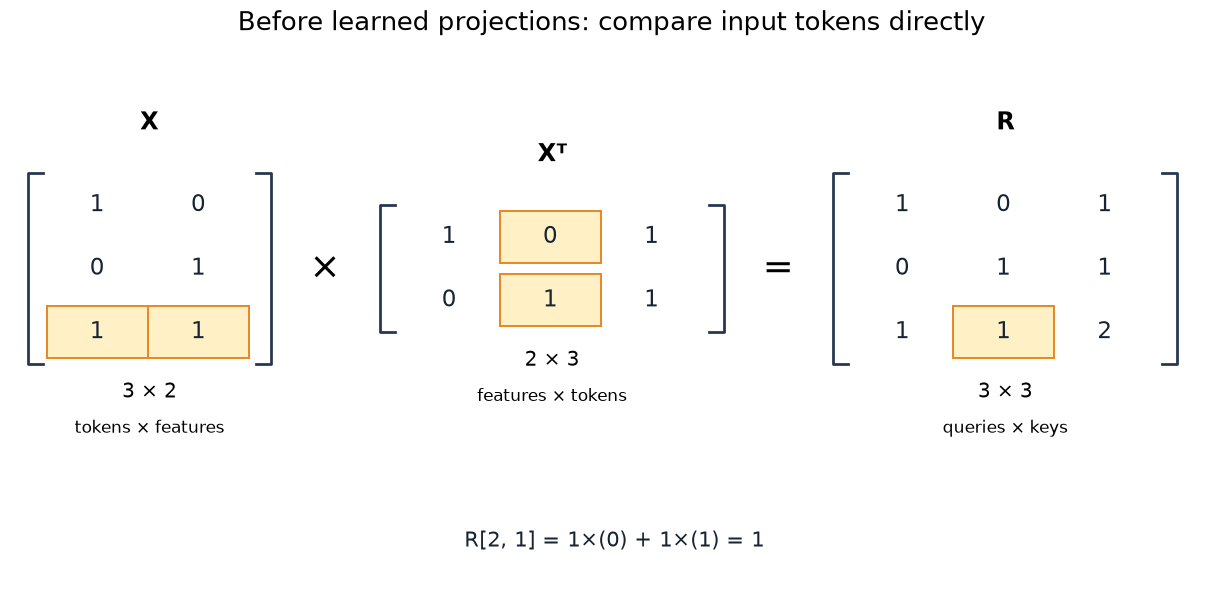

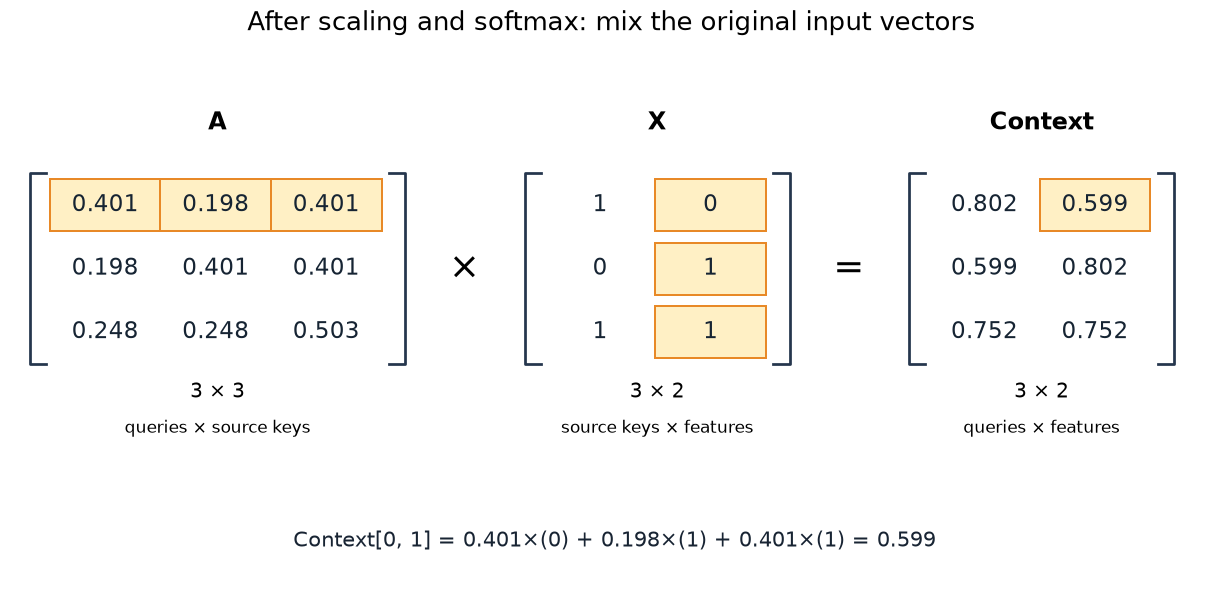

In [11]:
vis.show_unprojected_attention(raw_x, raw_weights, raw_context)

## 3. Learn the projections

Real attention learns `Q = query(x)`, `K = key(x)` and `V = value(x)` with three linear layers. They can give the same token different roles as a query, key and value. `SingleHeadAttention` uses one full-width set of query, key and value projections, with no head splitting.

Our batch has three sequences, each padded to length five, with nine numbers per token. A single head produces one 5×5 weight matrix per sequence.


In [12]:
x = torch.randn(3, 5, 9)
single = SingleHeadAttention(embedding_dimension=9).eval()
with torch.inference_mode():
    single_output, single_weights = single(x, need_weights=True)
print("Input:", tuple(x.shape))
print("Weights:", tuple(single_weights.shape))
print("First sequence's weights:\n", single_weights[0])
print("Output:", tuple(single_output.shape))


Input: (3, 5, 9)
Weights: (3, 5, 5)
First sequence's weights:
 tensor([[0.1750, 0.1628, 0.2104, 0.2092, 0.2427],
        [0.2151, 0.1671, 0.1362, 0.2955, 0.1861],
        [0.3038, 0.2535, 0.1397, 0.1654, 0.1376],
        [0.1274, 0.1498, 0.1995, 0.2235, 0.2997],
        [0.1990, 0.1550, 0.1514, 0.2513, 0.2434]])
Output: (3, 5, 9)


### Trace the learned projections

The three branches use the same input but different learned weights. For this single-head layer, all three projections keep width nine. Q and K produce one 5×5 score matrix per sequence; softmax runs over key columns, and the resulting weights mix V.


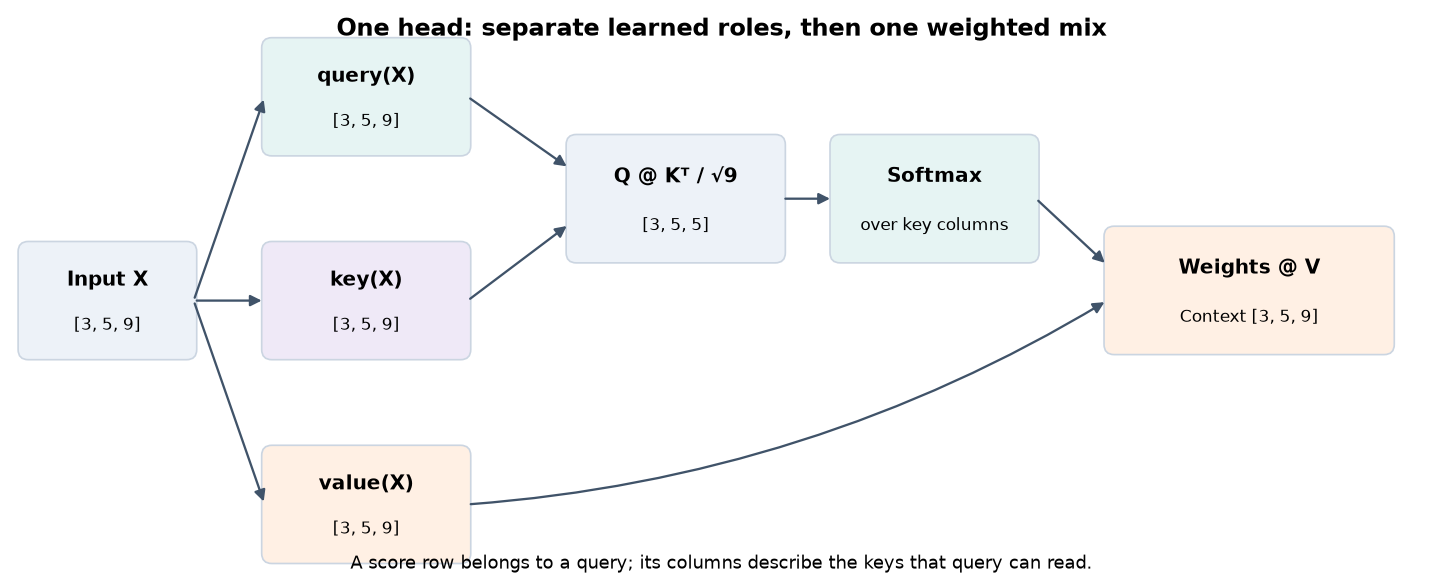

In [13]:
vis.show_projection_flow()


### Q: transform each token into a query

This controlled example uses three token rows with two input features, so every number fits on the page. It uses the actual `SingleHeadAttention` projection layers with fixed demonstration weights. The nine-feature randomly initialized layer above is a separate example of the same operation.

Q is the matrix of query vectors: each row is the transformed representation that compares with keys. `single.query(x)` performs `X × W_Q + b_Q` for each token. The displayed W_Q is `single.query.weight.T`, because PyTorch stores a Linear weight as `[output features, input features]`. The bias is added to every row. Highlighted Q[2,0] is `1×1 + 1×1 + 0 = 2`.


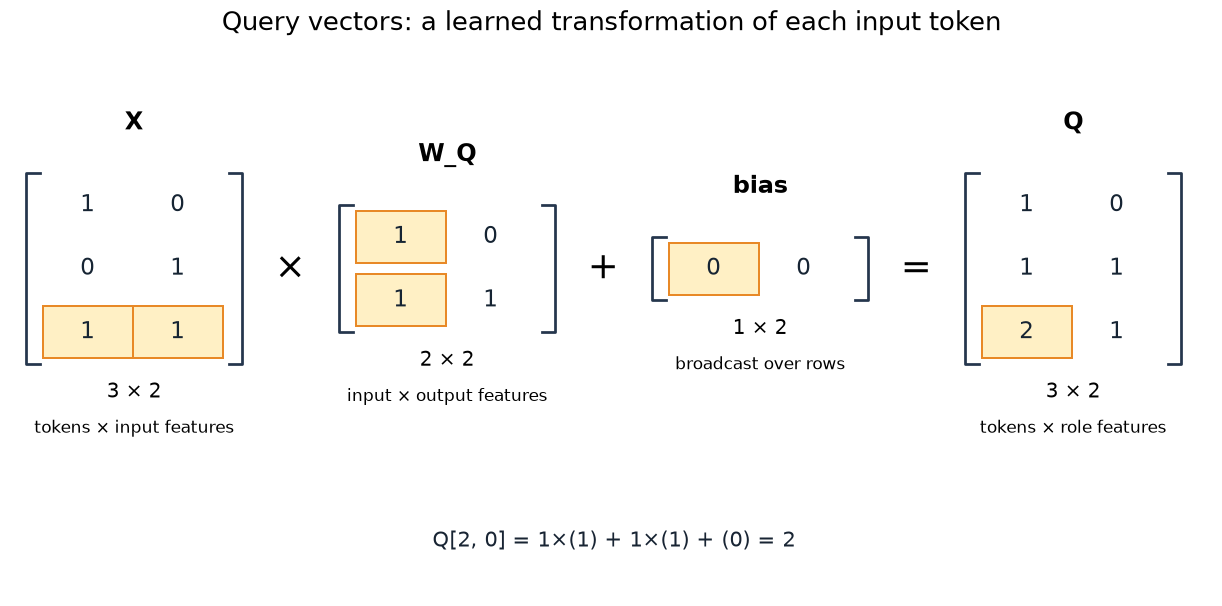

In [14]:
vis.show_projection("Q")


### K: build the vectors that queries compare against

K uses the same X but different weights and bias: `single.key(x)`. Its rows are key vectors. They are still associated with the same input-token positions, but their feature values can differ from Q.

The highlighted key feature shows cancellation: `1×1 + 1×(−1) + 0 = 0`. These are learned projections in a trained layer; here their values are chosen to make the arithmetic visible.


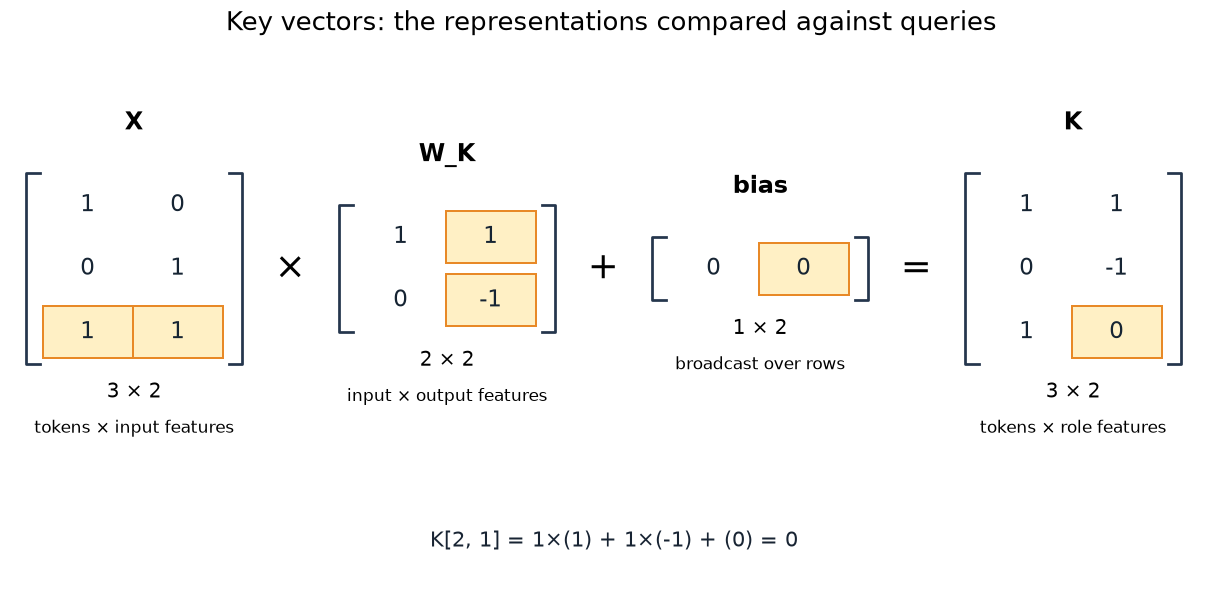

In [15]:
vis.show_projection("K")


### V: build the information that will be mixed

V is the value matrix, produced by `single.value(x)`. Keys determine comparison scores; values provide the vectors that those scores eventually mix.

The nonzero bias makes the broadcast visible: the highlighted V[1,1] is `0×0 + 1×3 + (−0.5) = 2.5`. Values may be negative even though attention weights are nonnegative.


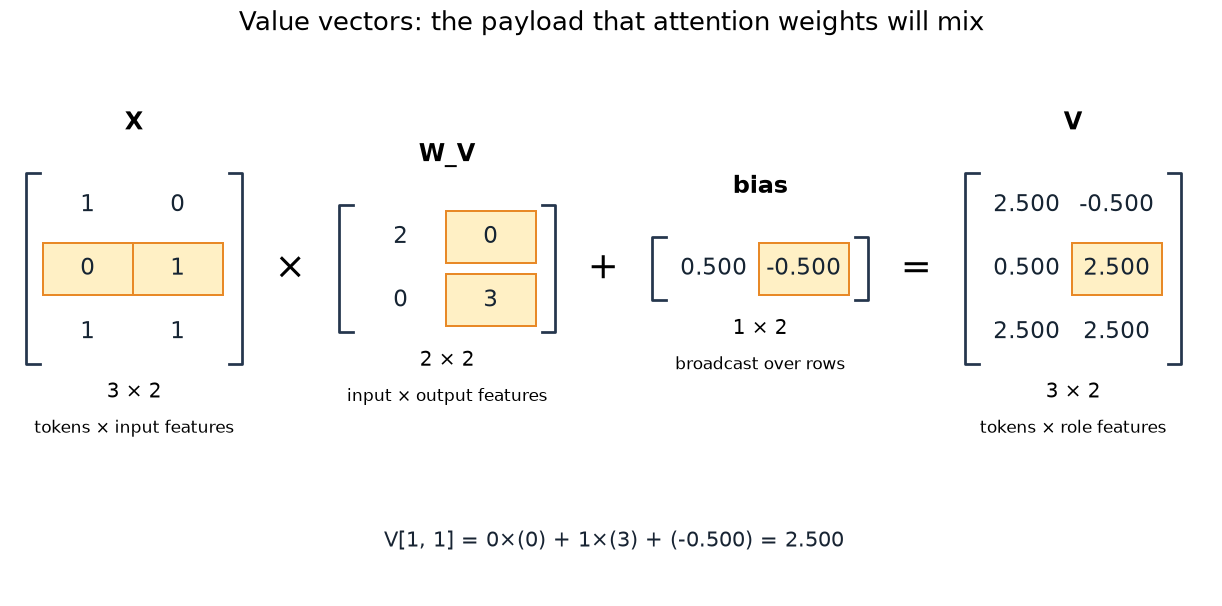

In [16]:
vis.show_projection("V")


### Transpose K so feature dimensions line up

Q is `[3 queries, 2 features]`, and K is `[3 keys, 2 features]`. Multiplying Q by K directly would have incompatible inner dimensions. `K.transpose(-2, -1)` gives `[2 features, 3 keys]`.

Transpose changes the axes, not the numbers: K[0,1] becomes Kᵀ[1,0]. Now every query row can meet every key column.


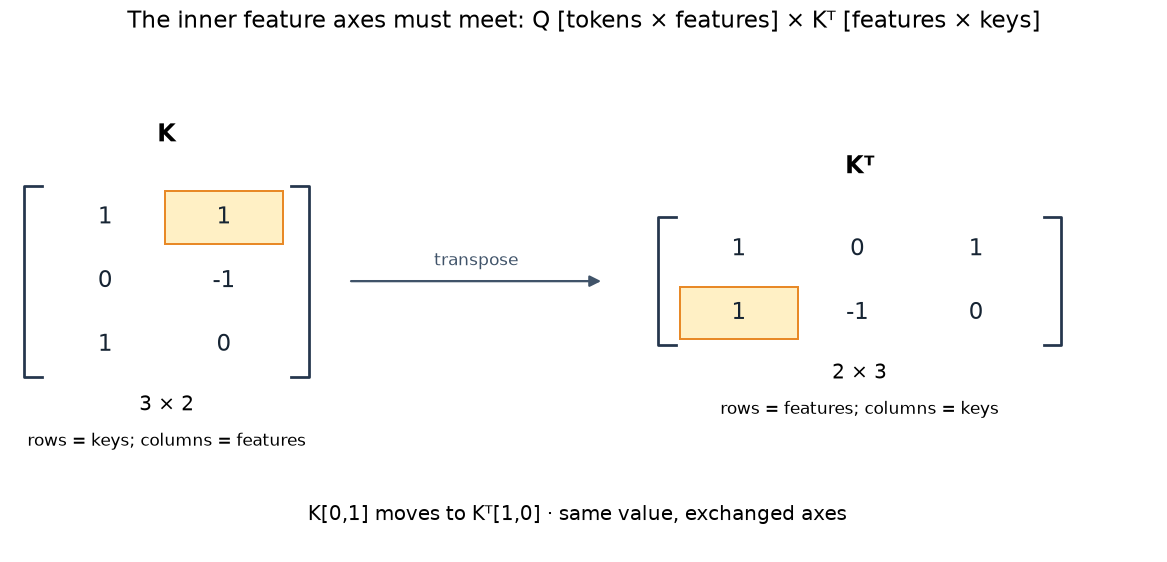

In [17]:
vis.show_key_transpose()


### Q × Kᵀ gives all query–key scores

The highlighted row/column pair shows one score; the resulting 3×3 matrix collects every pair. Its row index is a query position and column index is a key position.

A negative score is valid: Q[1] = [1,1] dotted with key 1 = [0,−1] gives `1×0 + 1×(−1) = −1`. These raw scores are not probabilities yet.


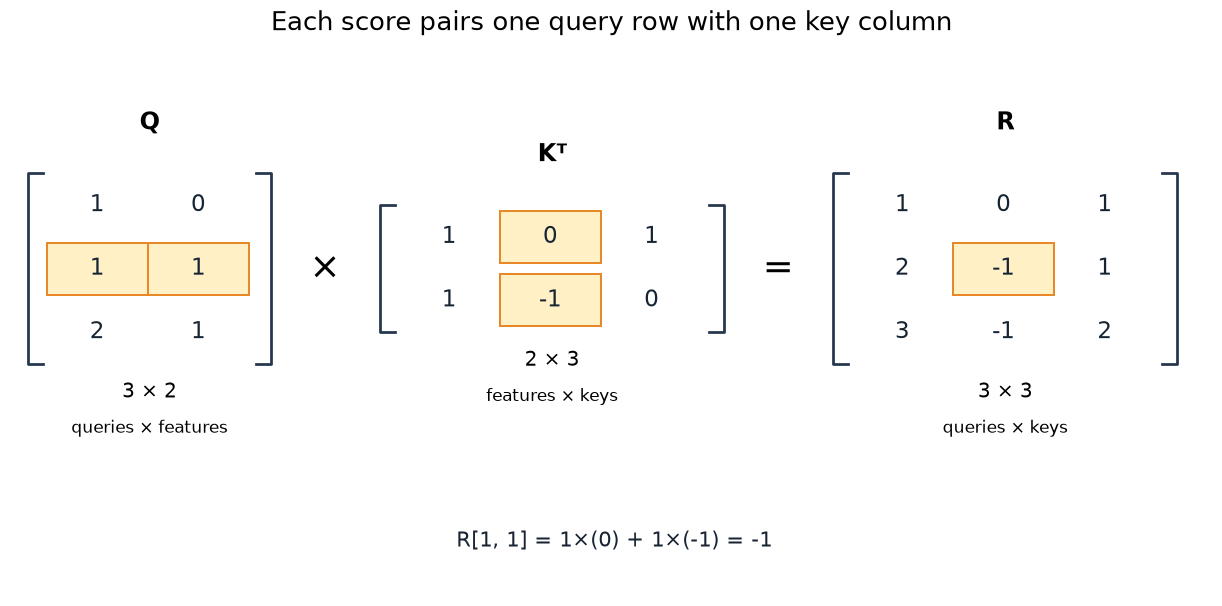

In [18]:
vis.show_score_product()


### Scale, then normalize each score row

The head has width two. Divide each raw score by √2 before softmax. For each row, exponentiate its entries and divide by that row's sum. The result A contains one attention distribution per query.

The displayed row calculation uses all three keys in its denominator. Normalizing the entire matrix at once would mix different queries and give the wrong operation.


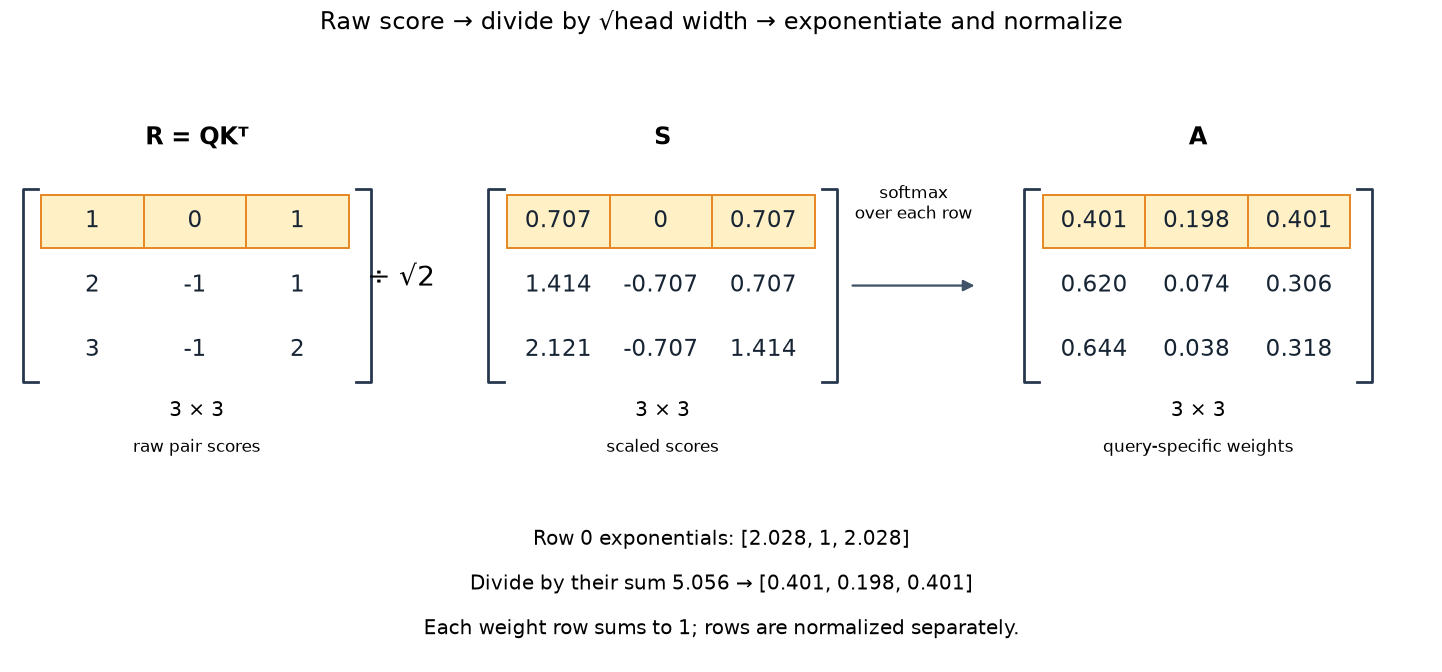

In [19]:
vis.show_score_normalization()


### A × V turns weights into context vectors

A is `[3 queries, 3 source keys]`; V is `[3 source keys, 2 value features]`. The shared key dimension is summed away, producing `[3 queries, 2 value features]`.

One row of A weights all rows of V. The highlighted output feature spells out those three contributions, including a negative value contribution. Each context row is the weighted information retrieved for one query.


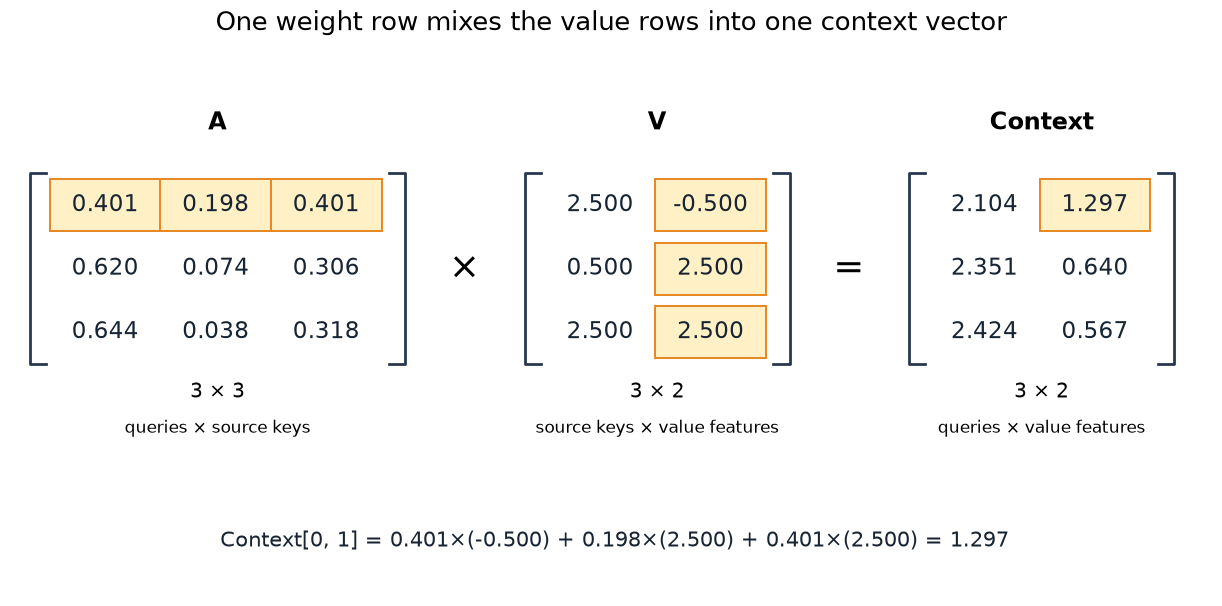

In [20]:
vis.show_value_product()


## 4. Multiple heads, first separately and then together

Three heads split the nine-dimensional embedding into widths of three. Each head learns its own relationships, computes a weighted average, and returns three numbers per token. Concatenating the three heads restores width nine; the final projection mixes information across heads.

`MultiHeadAttention` uses a loop and separate projections per head. `SelfAttentionEncoder` packs all heads into tensors shaped `(batch, heads, sequence, head width)` and computes them together. Both use $\sqrt{3}$ for scaling here.

The cell copies the loop model's parameters into the vectorized model so the comparison measures the calculation rather than two different random initializations.


In [21]:
separate = MultiHeadAttention(embedding_dimension=9, num_heads=3).eval()
vectorized = SelfAttentionEncoder(embed_dim=9, num_heads=3).eval()
with torch.no_grad():
    for name, projection in (("Q", vectorized.q_proj), ("K", vectorized.k_proj), ("V", vectorized.v_proj)):
        projection.weight.copy_(torch.cat([head[name].weight for head in separate.multihead_qkv]))
        projection.bias.copy_(torch.cat([head[name].bias for head in separate.multihead_qkv]))
    vectorized.proj.load_state_dict(separate.head_mesh.state_dict())
with torch.inference_mode():
    slow, slow_weights = separate(x, need_weights=True)
    packed, packed_weights = vectorized(x, need_weights=True)
print("Three heads:", tuple(packed_weights.shape))
print("Output:", tuple(packed.shape))
print("Maximum loop/vectorized difference:", (slow - packed).abs().max().item())
torch.testing.assert_close(slow, packed)
torch.testing.assert_close(slow_weights, packed_weights)


Three heads: (3, 3, 5, 5)
Output: (3, 5, 9)
Maximum loop/vectorized difference: 5.960464477539063e-08


### See how heads are packed

This diagram uses one batch, three tokens, six projected features and two heads, so all eighteen numbers fit on the page. The first three features of each token belong to head 0 and the last three to head 1. Reshape groups the features; transpose moves the head axis in front of the token axis. No token features are lost or mixed by this reindexing.

The next heatmaps come from the actual three-head layer above. They share a 0–1 color scale. Different patterns are numerical differences between randomly initialized heads, not evidence that particular heads understand grammar. Select a head and query row to read its weights as a bar chart.


/mnt/projects/ai/ai_projects/projects/attention-is-all-you-need/attention_visuals.py:290: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(top=.77, bottom=.17, wspace=.35)


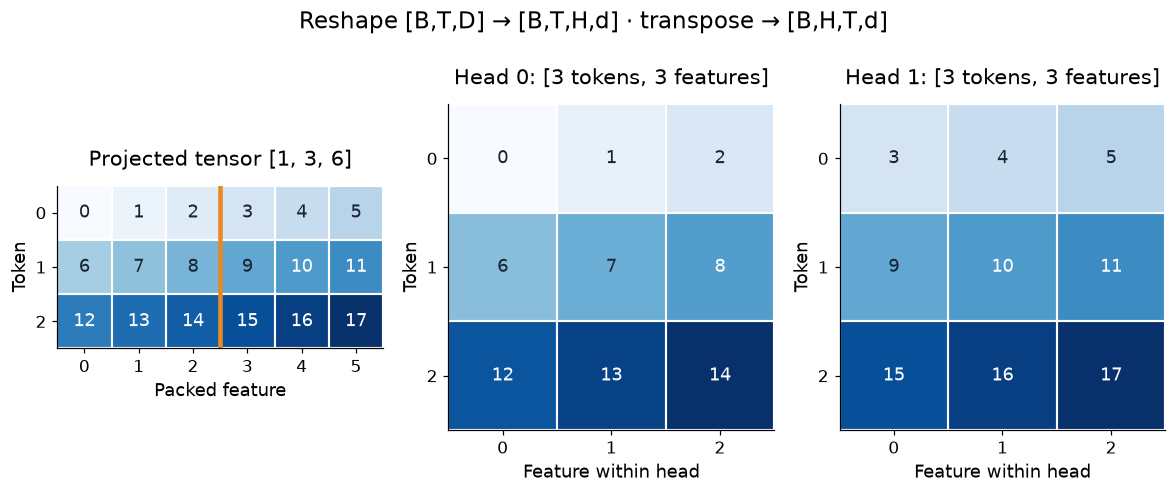

/mnt/projects/ai/ai_projects/projects/attention-is-all-you-need/attention_visuals.py:297: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(top=.77, bottom=.17, wspace=.35)


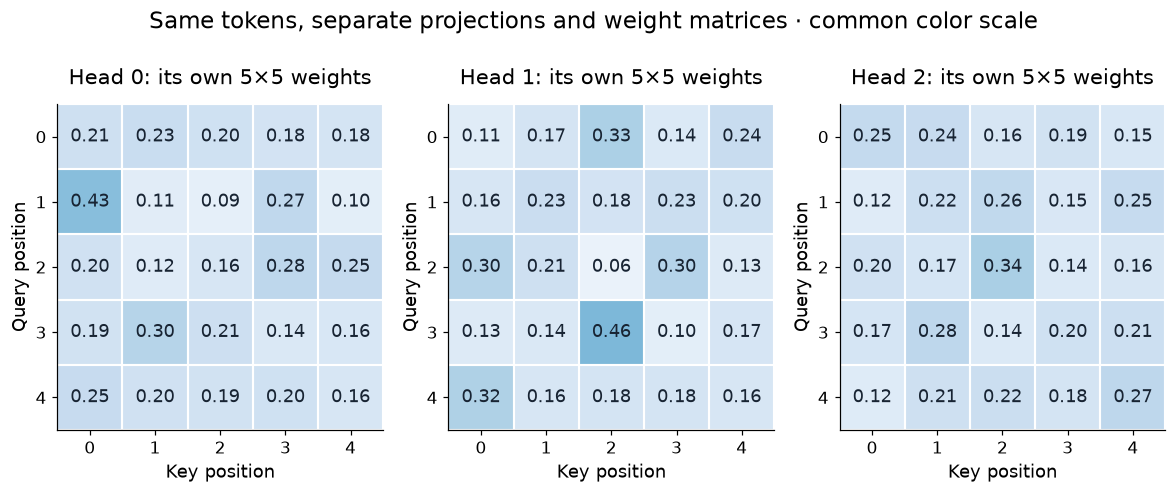

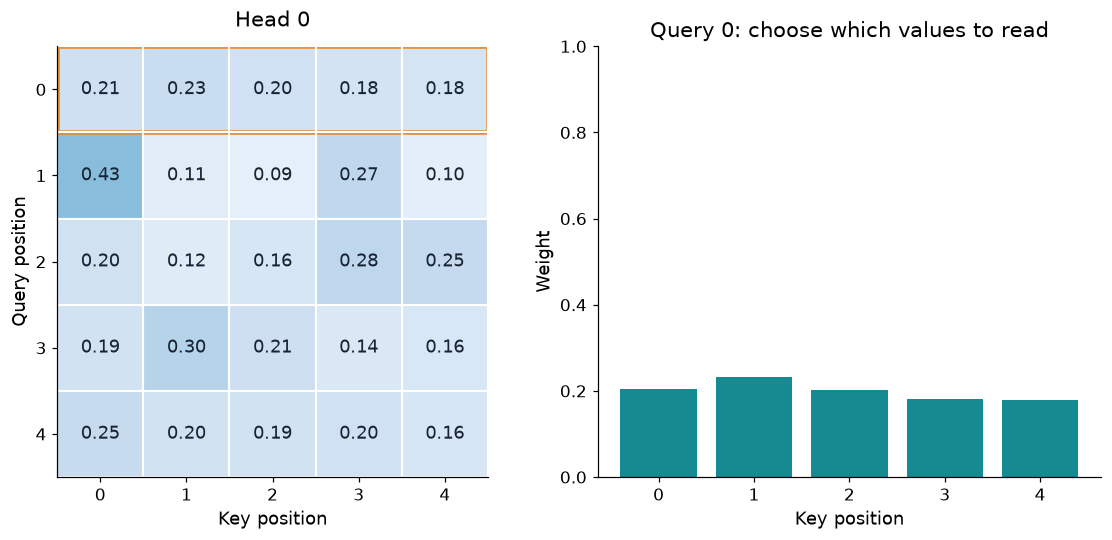

In [22]:
head_controls = vis.show_head_packing(packed_weights)


### Merge head contexts by concatenating their features

Each synthetic head here produces two features for each of two tokens. `context.transpose(1, 2).flatten(2)` changes `[batch, heads, tokens, head features]` into `[batch, tokens, all head features]`.

Concatenation does not add or average the heads; it places their features side by side. The two matrices on the left become the four-feature matrix on the right without changing any number.


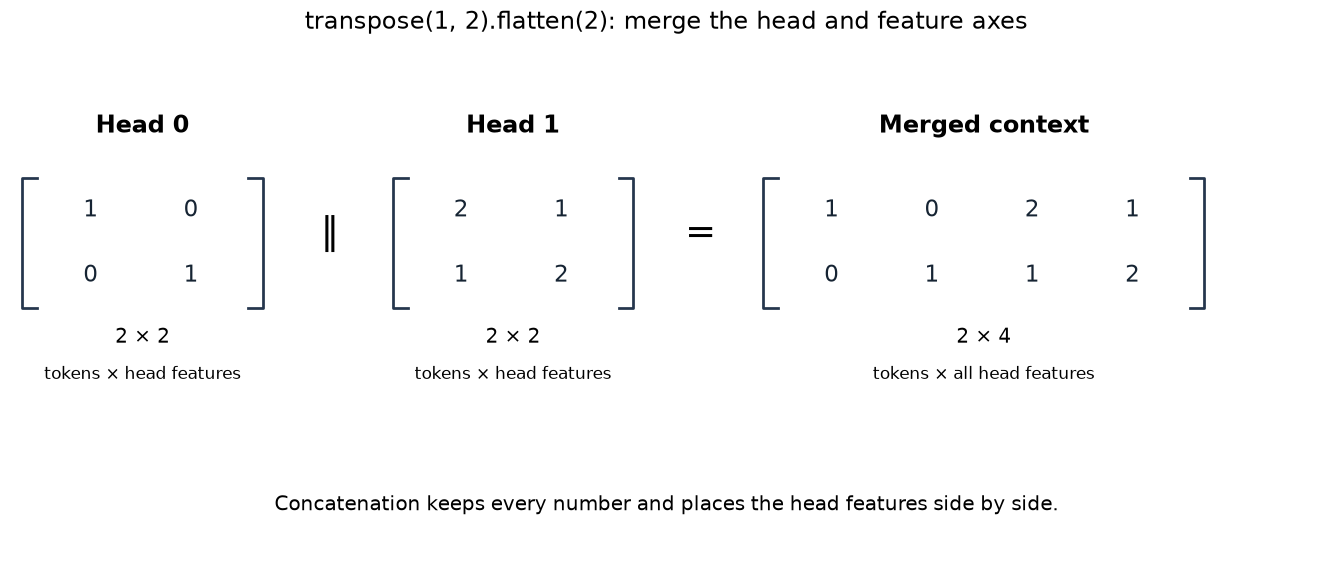

In [23]:
vis.show_head_merge()


### Apply the output projection to the merged features

After concatenation, `out_proj(merged)` performs another linear map. This example uses the actual output-projection module from `Attention(embedding_dimension=4, num_heads=2)` with controlled weights.

Each output feature can depend on features from different heads. The highlighted calculation is `1×1 + 0×0 + 2×1 + 1×0 = 3`. This projection mixes the heads while keeping one output row per query.


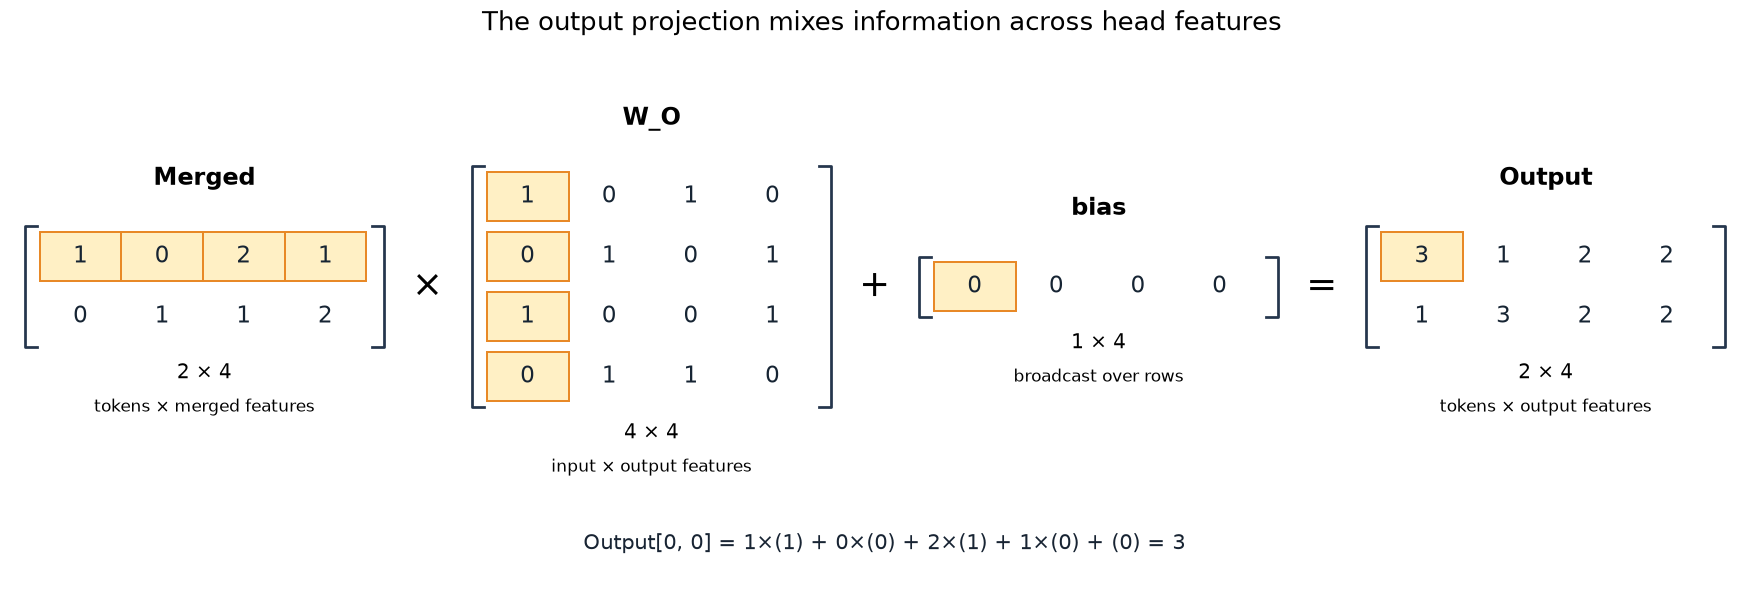

In [24]:
vis.show_output_projection()


## 5. Ignore padded keys

The sequence lengths are 3, 5 and 4. The mask uses **True/1 for real source tokens** and False/0 for padding. A `(batch, keys)` mask becomes `(batch, 1, 1, keys)` and broadcasts over heads and query rows.

The first sequence cannot read columns 3 and 4. Padding masks remove **keys**; they don't erase padded query rows. Later training must also exclude padded targets from the loss. If every key for a row is blocked, its attention weights and context are zero; an output projection can still add its bias.


In [25]:
padding_mask = torch.tensor([
    [1, 1, 1, 0, 0],
    [1, 1, 1, 1, 1],
    [1, 1, 1, 1, 0],
], dtype=torch.bool)
encoder = SelfAttention(embed_dim=9, num_heads=3).eval()
with torch.inference_mode():
    encoder_output, encoder_weights = encoder(x, padding_mask, need_weights=True)
print("Padding mask:\n", padding_mask)
print("Broadcast mask shape:", tuple(make_attention_mask(padding_mask, 5, 5).shape))
print("First sequence, first head:\n", encoder_weights[0, 0])
assert torch.count_nonzero(encoder_weights[0, :, :, 3:]) == 0


Padding mask:
 tensor([[ True,  True,  True, False, False],
        [ True,  True,  True,  True,  True],
        [ True,  True,  True,  True, False]])
Broadcast mask shape: (3, 1, 1, 5)
First sequence, first head:
 tensor([[0.5244, 0.2441, 0.2314, 0.0000, 0.0000],
        [0.3879, 0.3082, 0.3039, 0.0000, 0.0000],
        [0.2007, 0.4291, 0.3702, 0.0000, 0.0000],
        [0.5606, 0.2559, 0.1835, 0.0000, 0.0000],
        [0.2526, 0.3997, 0.3477, 0.0000, 0.0000]])


### Padding blocks columns

The gray columns mark source keys 3 and 4 as unavailable. Every query row still exists, including padded query positions. Their outputs must be handled separately when building a loss.


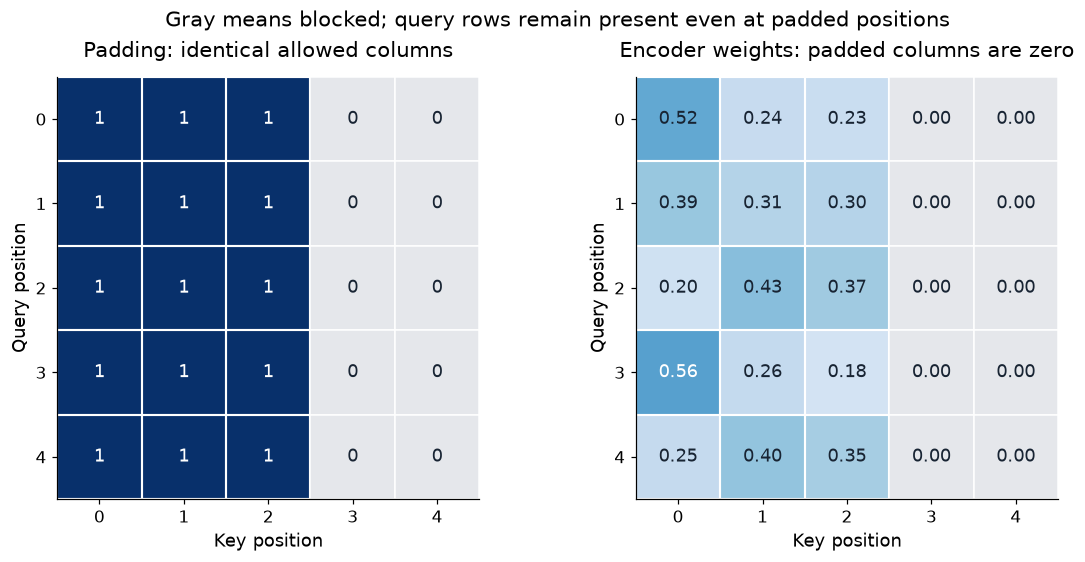

In [26]:
vis.show_padding(padding_mask, encoder_weights)


## 6. Decoder causality

A decoder's token at position `i` can read keys at positions `j <= i`. It cannot read later target tokens. This gives a lower-triangular mask; combine it with the padding mask using AND.

For the first sequence, row 0 can read only column 0, row 1 can read columns 0–1, and row 2 can read columns 0–2. Columns 3–4 are blocked as padding even for later queries.


In [27]:
combined = make_attention_mask(padding_mask, 5, 5, causal=True)
decoder = SelfAttention(embed_dim=9, num_heads=3, causal=True).eval()
with torch.inference_mode():
    decoder_output, decoder_weights = decoder(x, padding_mask, need_weights=True)
print("Combined mask, first sequence:\n", combined[0, 0].int())
print("First decoder head:\n", decoder_weights[0, 0])
assert torch.count_nonzero(decoder_weights.triu(1)) == 0
print("Output:", tuple(decoder_output.shape))


Combined mask, first sequence:
 tensor([[1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 0, 0]], dtype=torch.int32)
First decoder head:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4012, 0.5988, 0.0000, 0.0000, 0.0000],
        [0.3276, 0.3723, 0.3001, 0.0000, 0.0000],
        [0.3107, 0.2428, 0.4464, 0.0000, 0.0000],
        [0.3073, 0.2846, 0.4081, 0.0000, 0.0000]])
Output: (3, 5, 9)


### Inspect masks before and after softmax

Toggle padding and causality independently. The four panels show allowed pairs → masked scores → normalized weights → the selected query row. Blocked scores are −∞ before softmax, so their weights are exactly zero. This also shows why multiplying weights by a mask after softmax would leave their sum too small without renormalization.

Try query row 4 to see padding remove two otherwise visible keys; query row 0 shows how causality leaves just one key.


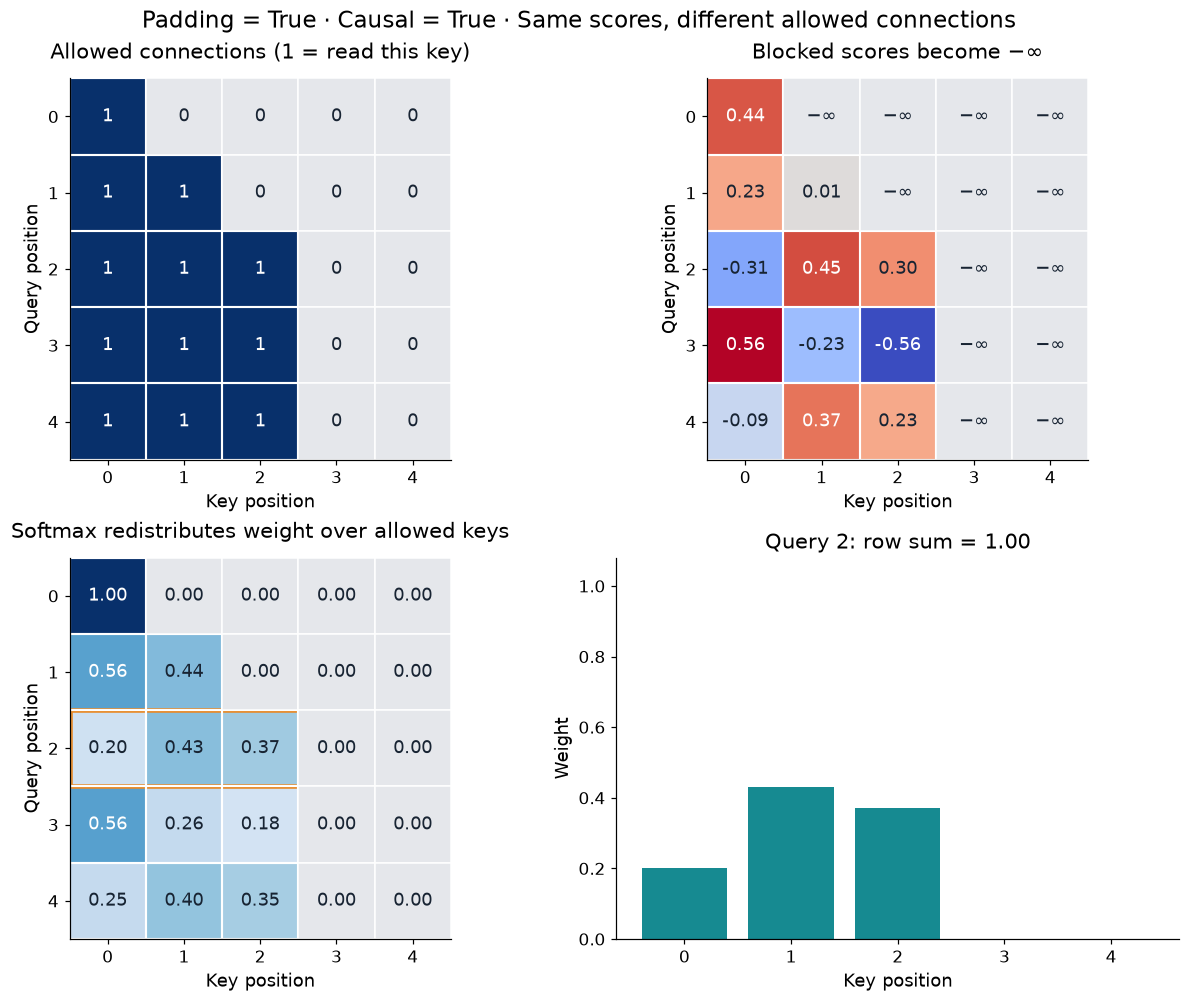

In [28]:
mask_controls = vis.show_masks(encoder, x, padding_mask)


## 7. Test for future-token leakage

Change only the final token. With dropout off, outputs for the first four query positions must stay the same. This checks the behavior of the mask, not just what the matrix looks like.


In [29]:
changed = x.clone()
changed[:, -1] += 100
with torch.inference_mode():
    before = decoder(x)
    after = decoder(changed)
error = (before[:, :-1] - after[:, :-1]).abs().max().item()
print("Earlier-token maximum change:", error)
torch.testing.assert_close(before[:, :-1], after[:, :-1])


Earlier-token maximum change: 0.0


### Measure future-token leakage

The following comparison copies the same parameters and changes only whether the layer is causal. All five positions are treated as real tokens here, so padding does not confound the experiment. Changing the final input token must leave earlier causal outputs unchanged. The final output itself is allowed to respond.


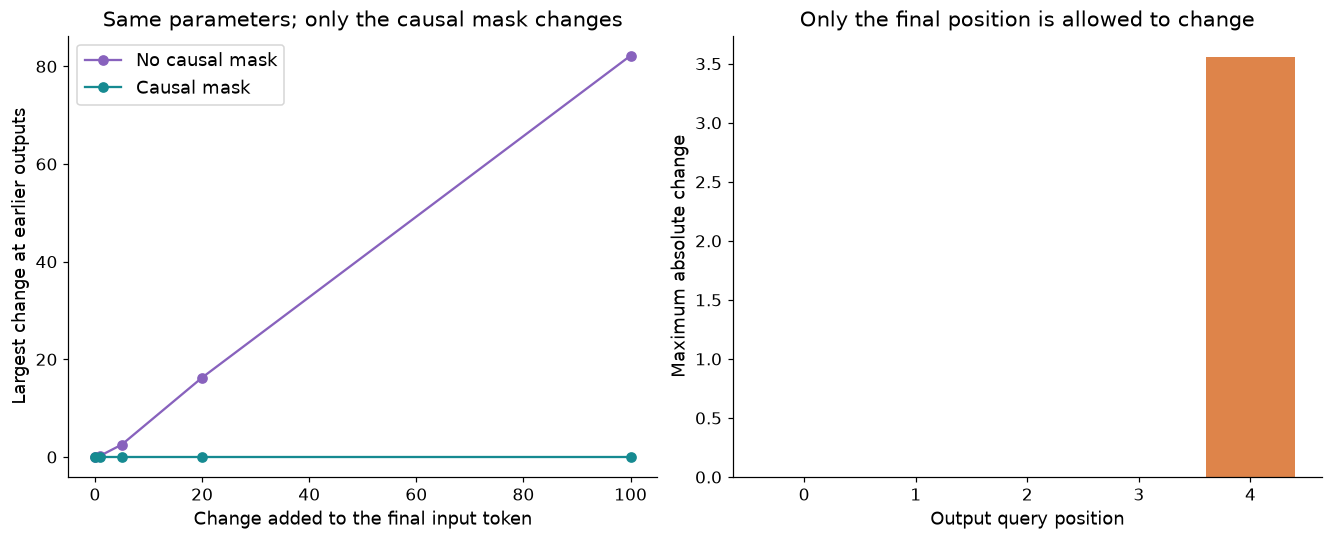

In [30]:
vis.show_future_isolation(decoder, x)


## 8. Cross-attention

The source represents English and the target represents French. Target vectors provide queries; source vectors provide keys and values. Here source length is five and target length is seven, so each head's weights have shape `(batch, heads, 7, 5)`. Output length follows the target.

The mask must have the **source length**, because it excludes source keys. Cross-attention reads the encoded source without a causal mask; decoder self-attention handles target causality separately. These are random embeddings used to check shapes, not English/French tokenization.


In [31]:
target = torch.randn(3, 7, 9)
cross = CrossAttention(embed_dim=9, num_heads=3).eval()
with torch.inference_mode():
    cross_output, cross_weights = cross(src=x, tgt=target, attention_mask=padding_mask, need_weights=True)
print("Source:", tuple(x.shape), "Target:", tuple(target.shape))
print("Weights:", tuple(cross_weights.shape))
print("First target query's source weights:", cross_weights[0, 0, 0])
print("Output:", tuple(cross_output.shape))
assert cross_output.shape == target.shape
assert torch.count_nonzero(cross_weights[0, :, :, 3:]) == 0


Source: (3, 5, 9) Target: (3, 7, 9)
Weights: (3, 3, 7, 5)
First target query's source weights: tensor([0.4825, 0.3789, 0.1386, 0.0000, 0.0000])
Output: (3, 7, 9)


### Rectangular attention is expected

There are seven target queries but five source keys. After splitting into three heads, the score/weight tensor is `[3, 3, 7, 5]`. The softmax axis is the five-key axis; mixing values and merging heads returns `[3, 7, 9]`. The gray source columns in the heatmap are padding. These are synthetic embeddings, not learned word alignments.


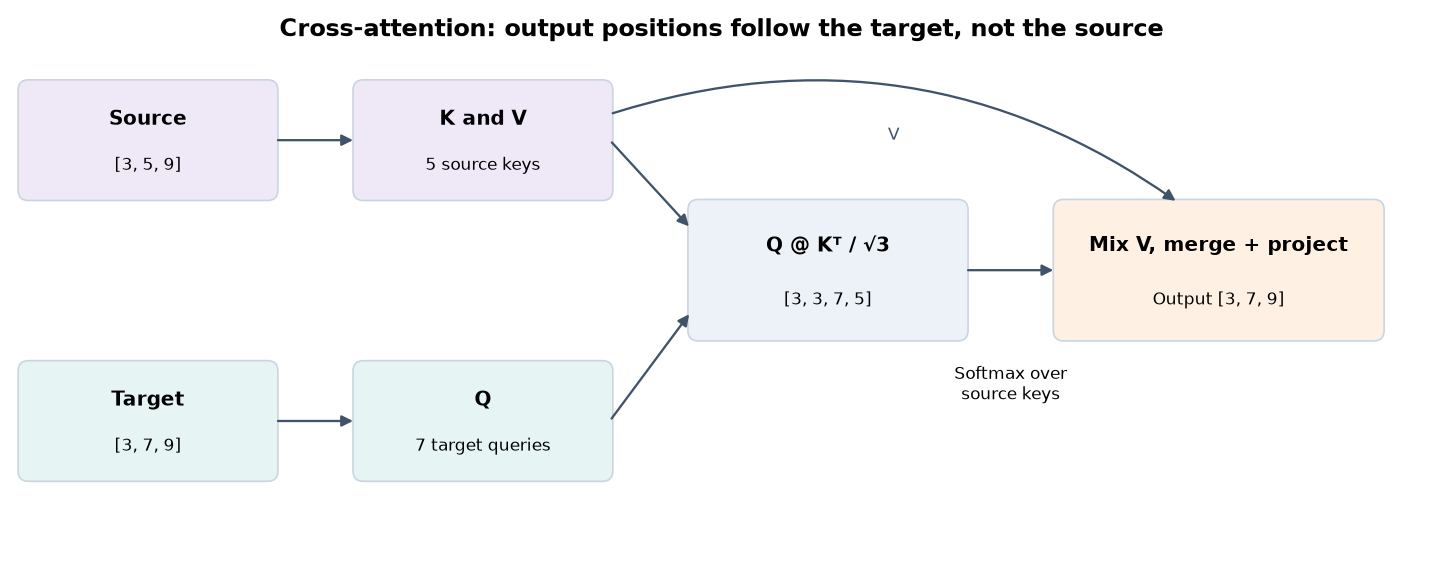

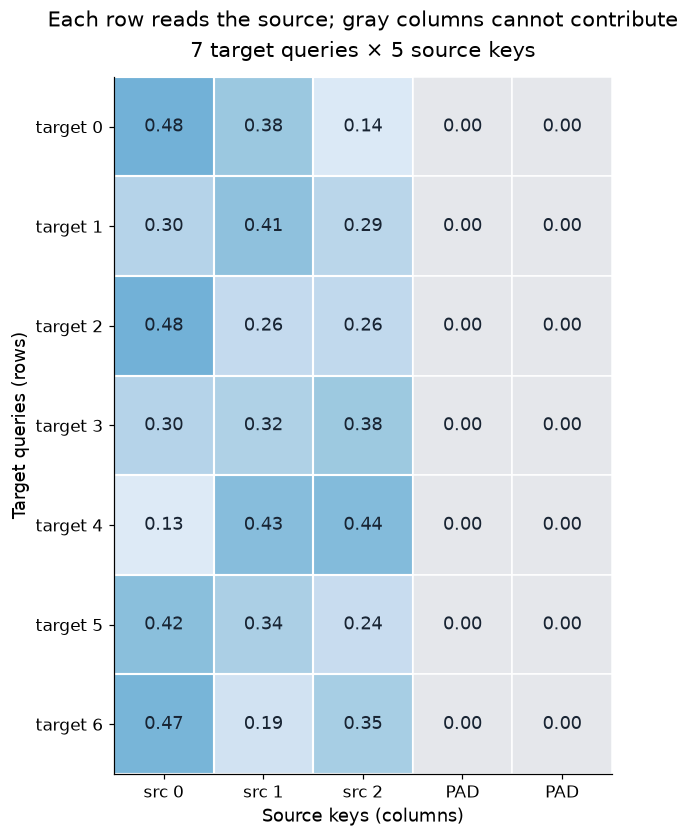

In [32]:
vis.show_cross_attention(padding_mask, cross_weights)


## 9. Explicit and efficient attention

`Attention` supports self-attention and cross-attention through the same interface. Its constructor is `Attention(embedding_dimension, num_heads, attn_dropout)` and its forward call is `forward(src, tgt=None, attention_mask=None, causal=False)`. The four projection names stay `q_proj`, `k_proj`, `v_proj` and `out_proj` for the later model.

The default path uses `torch.nn.functional.scaled_dot_product_attention`. PyTorch selects the kernel based on the device and inputs; CPU correctness does not prove GPU FlashAttention performance. `fused_attn=False` exposes the explicit calculation for comparison, and `need_weights=True` uses that explicit path to show the matrix. Both options use the same projections and masking rules.

Use `eval()` plus `torch.inference_mode()` to inspect outputs without dropout or gradient recording. During training, attention dropout and gradients stay active.


In [33]:
manual = Attention(embedding_dimension=9, num_heads=3, fused_attn=False).eval()
efficient = Attention(embedding_dimension=9, num_heads=3).eval()
efficient.load_state_dict(manual.state_dict())
with torch.inference_mode():
    for label, arguments in (
        ("Encoder", {"attention_mask": padding_mask}),
        ("Decoder", {"attention_mask": padding_mask, "causal": True}),
        ("Cross-attention", {"tgt": target, "attention_mask": padding_mask}),
    ):
        reference = manual(x, **arguments)
        result = efficient(x, **arguments)
        print(label, tuple(result.shape), "max difference:", (reference - result).abs().max().item())
        torch.testing.assert_close(reference, result, atol=1e-6, rtol=1e-5)
print("Final cross-attention output, first target token:\n", result[0, 0])


Encoder (3, 5, 9) max difference: 8.940696716308594e-08
Decoder (3, 5, 9) max difference: 7.450580596923828e-08
Cross-attention (3, 7, 9) max difference: 6.705522537231445e-08
Final cross-attention output, first target token:
 tensor([-0.0565,  0.0765, -0.3019,  0.0328, -0.1036, -0.0850, -0.2230,  0.1211,
         0.1375])


### Compare the final output matrices

The first two panels use the same color range. The third shows absolute differences with its own much smaller range, so its visible color is not a large output change. This checks numerical agreement on CPU; it does not measure speed or establish a GPU kernel result.


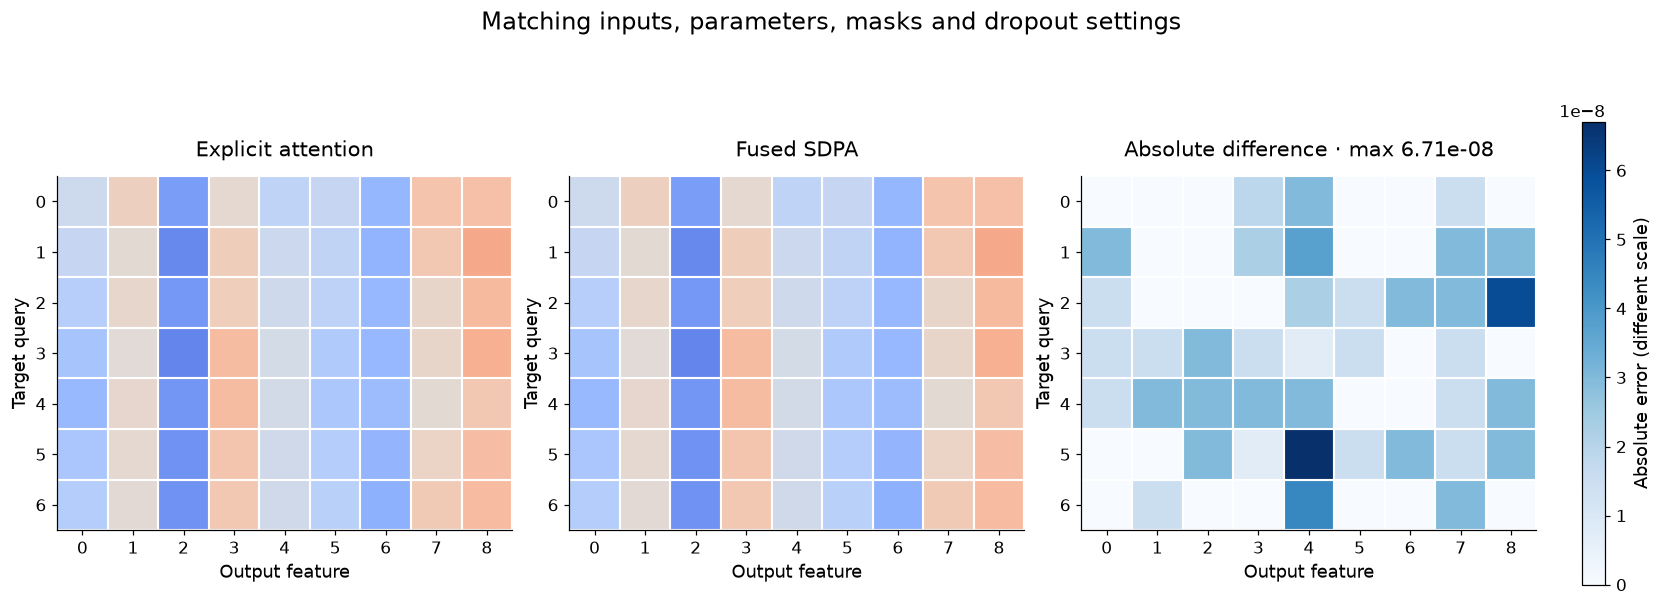

In [34]:
vis.show_path_comparison(manual, efficient, x, target, padding_mask)


## 10. Gradients still flow

The same module can train: the projections are registered parameters, and the explicit and efficient paths both support autograd. This small calculation uses mean squared output as a diagnostic objective, not a translation loss. It runs one backward pass without updating weights.


In [35]:
trainable = Attention(embedding_dimension=9, num_heads=3, attn_dropout=0.1)
training_input = x.clone().requires_grad_()
output = trainable(training_input, attention_mask=padding_mask, causal=True)
loss = output.square().mean()
loss.backward()
print("Diagnostic loss:", loss.item())
print("Input gradient norm:", training_input.grad.norm().item())
for name, parameter in trainable.named_parameters():
    assert torch.isfinite(parameter.grad).all()
    print(name, "gradient norm:", parameter.grad.norm().item())


Diagnostic loss: 0.07438642531633377
Input gradient norm: 0.02620069868862629
q_proj.weight gradient norm: 0.009396307170391083
q_proj.bias gradient norm: 0.005650654900819063
k_proj.weight gradient norm: 0.01223116647452116
k_proj.bias gradient norm: 5.514868561817821e-10
v_proj.weight gradient norm: 0.11386767029762268
v_proj.bias gradient norm: 0.0774950459599495
out_proj.weight gradient norm: 0.13568276166915894
out_proj.bias gradient norm: 0.12193118780851364


### Follow the backward pass

The reverse arrow shows that the diagnostic objective sends gradients back through the output projection and attention calculation. The bars are actual parameter-gradient norms. A very small key-bias gradient is expected here: adding the same key bias shifts every key score in a query row equally, and softmax is unchanged by a common shift. This cell performs no optimizer update.


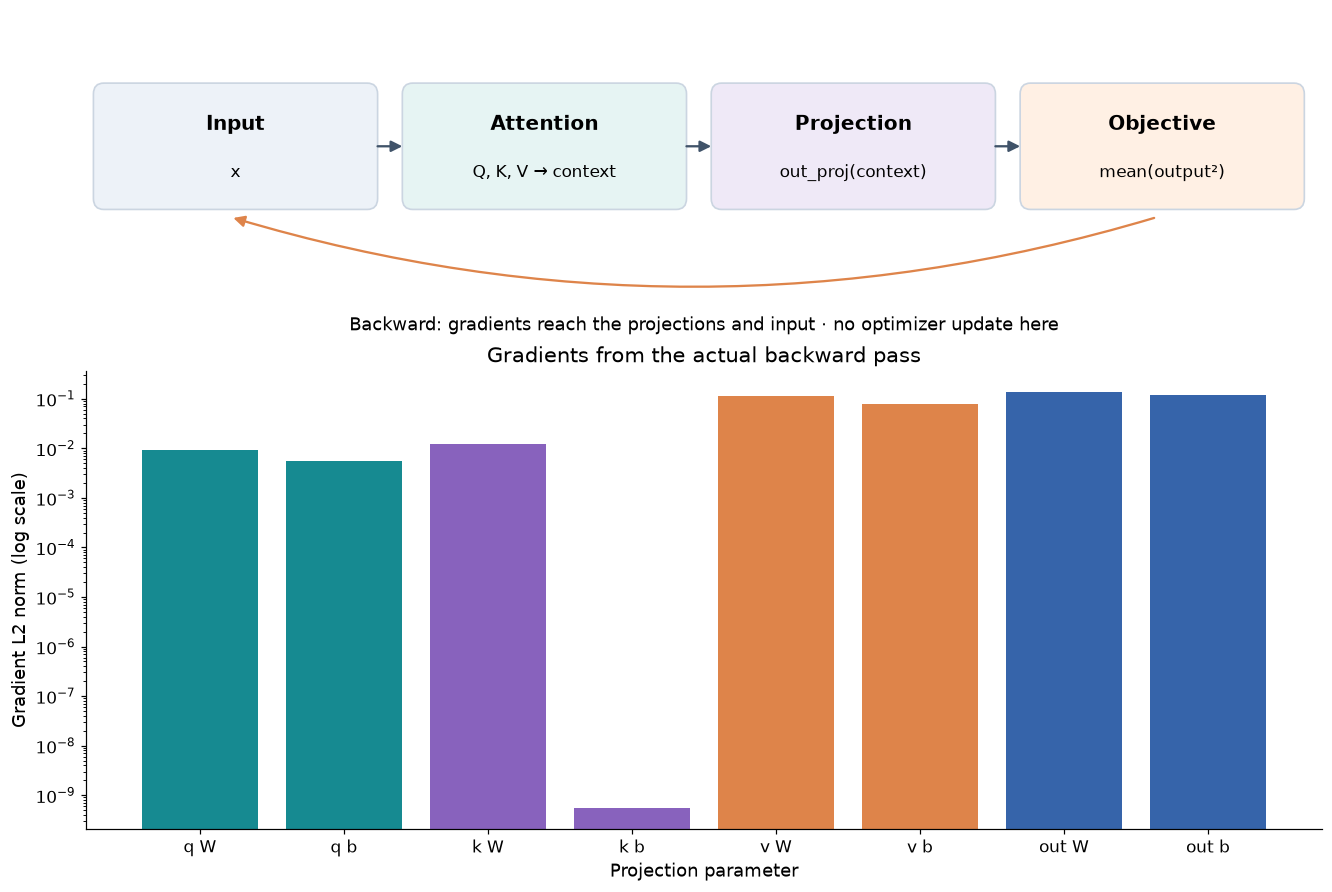

In [36]:
vis.show_gradient_flow(trainable)


## Run the complete example

The same examples and final outputs are available from `uv run --frozen python attention.py`, or `./ai run attention-is-all-you-need` from workspace home. The script checks the reference and efficient outputs and prints the final tensor.

Next are tokenization and paired-text preparation in `tokenizer.py` and `prepare_data.py`. The encoder–decoder assembly, training and real translation are still waiting for implementation.


In [37]:
from attention import run_demo
summary = run_demo()
print("Final comparison errors:", summary["errors"])


Attention | torch 2.14.1+cpu | device=cpu | seed=7

1. A weighted average
Weights: tensor([[[0.5000, 0.5000]]])
Context: tensor([[[4., 6.]]]) (expected [4, 6])

Attention without learned projections: Q = K = V = X
Input X:
 tensor([[[1., 0.],
         [0., 1.]]])
Weights from X @ X.T / sqrt(2):
 tensor([[[0.6698, 0.3302],
         [0.3302, 0.6698]]])
Context (weights @ X):
 tensor([[[0.6698, 0.3302],
         [0.3302, 0.6698]]])

2. Single-head and multi-head attention
SingleHeadAttention: (3, 5, 9)
MultiHeadAttention: (3, 5, 9)
SelfAttentionEncoder: (3, 5, 9)

3. Encoder padding and decoder causality
Source mask (True = allowed key):
 tensor([[ True,  True,  True, False, False],
        [ True,  True,  True,  True,  True],
        [ True,  True,  True,  True, False]])
First decoder attention head:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4283, 0.5717, 0.0000, 0.0000, 0.0000],
        [0.3236, 0.3354, 0.3410, 0.0000, 0.0000],
        [0.4455, 0.3418, 0.2127, 0.0000